<a href="https://colab.research.google.com/github/Yur58/Fundamentos-de-Inteligencia-artificial/blob/main/Actividad_An%C3%A1lisis_de_Sentimiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
![ ! -f "text_analytics_-_sentiment_analysis_-_twitter.csv" ] && wget https://gitlab.com/nemog3762/resources/-/raw/main/datasets/text_analytics_-_sentiment_analysis_-_twitter.csv

In [4]:
import pandas as pd
import spacy
# Leer el archivo CSV
df = pd.read_csv("text_analytics_-_sentiment_analysis_-_twitter.csv")

# Mostrar las primeras filas
print("Primeras filas del dataset:")
display(df.head())

# Mostrar las columnas disponibles
print("\nColumnas disponibles:")
print(df.columns.tolist())

# Crear variable binaria 'Negative' → 1 si el sentimiento es negativo (<0)
df['Negative'] = (df['Avg'] < 0).astype(int)


# Mostrar las nuevas columnas
print("\nColumnas con las nuevas variables:")
display(df[['Tweet', 'Avg', 'Negative']].head())

# Ver distribución de ambas variables
print("\nDistribución de las variables binarias:")
print(df[['Negative']].value_counts())



Primeras filas del dataset:


,Tweet,Avg
0,"I have to say, Apple has by far the best custo...",2.0
1,iOS 7 is so fricking smooth & beautiful!! #Tha...,2.0
2,LOVE U @APPLE,1.8
3,"Thank you @apple, loving my new iPhone 5S!!!!!...",1.8
4,.@apple has the best customer service. In and ...,1.8



Columnas disponibles:
['Tweet', 'Avg']

Columnas con las nuevas variables:


,Tweet,Avg,Negative
0,"I have to say, Apple has by far the best custo...",2.0,0
1,iOS 7 is so fricking smooth & beautiful!! #Tha...,2.0,0
2,LOVE U @APPLE,1.8,0
3,"Thank you @apple, loving my new iPhone 5S!!!!!...",1.8,0
4,.@apple has the best customer service. In and ...,1.8,0



Distribución de las variables binarias:
Negative
0           640
1           541
Name: count, dtype: int64


In [27]:
import re
from spacy.lang.en.stop_words import STOP_WORDS

nlp = spacy.load("en_core_web_sm")

def preprocess_spacy(text):
    # 1️⃣ Pasar a minúsculas
    text = text.lower()

    # 2️⃣ Eliminar solo los caracteres especiales y URLs (pero dejar palabras)
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)  # eliminar URLs
    text = re.sub(r"[^a-zA-Z\s]", "", text)              # eliminar signos, números y símbolos

    # 3️⃣ Procesar con spaCy
    doc = nlp(text)

    # 4️⃣ Lematizar y eliminar stopwords
    tokens = [
        token.lemma_ for token in doc
        if not token.is_stop and not token.is_punct and token.text.strip() != ""
    ]

    # 5️⃣ Unir las palabras limpias
    return " ".join(tokens)

# Aplicar la función a toda la columna de tweets
df["Tweet_clean"] = df["Tweet"].apply(preprocess_spacy)

# Verificar el resultado
df[["Tweet", "Tweet_clean"]].head()


,Tweet,Tweet_clean
0,"I have to say, Apple has by far the best custo...",apple far good customer care service receive a...
1,iOS 7 is so fricking smooth & beautiful!! #Tha...,ios fricke smooth beautiful thanxapple apple
2,LOVE U @APPLE,love u apple
3,"Thank you @apple, loving my new iPhone 5S!!!!!...",thank apple love new iphone s apple iphone pic...
4,.@apple has the best customer service. In and ...,apple good customer service new phone min


In [32]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# Crear el vectorizador (puedes mantener los filtros min_df y max_df si quieres)
vectorizer = CountVectorizer(min_df=5)

# Ajustar y transformar los textos limpios
X = vectorizer.fit_transform(df["Tweet_clean"])

# Obtener el total de apariciones de cada palabra
word_counts = X.sum(axis=0).A1  # convierte la matriz dispersa a array

# Crear un DataFrame ordenado por frecuencia
word_freq = pd.DataFrame({
    "Palabra": vectorizer.get_feature_names_out(),
    "Frecuencia": word_counts
}).sort_values(by="Frecuencia", ascending=False)

pd.set_option('display.max_rows', None)  # mostrar todas las filas
display(word_freq)
pd.reset_option('display.max_rows')      # opcional, volver al valor por defecto


,Palabra,Frecuencia
10,apple,1331
146,iphone,331
204,not,157
199,new,113
145,ipad,91
217,phone,86
151,itune,77
149,ipod,73
150,ipodplayerpromo,60
9,app,54


In [33]:
from sklearn.model_selection import train_test_split

# Dividir los datos en entrenamiento y prueba
# X son los textos limpios y y la variable objetivo (por ejemplo, Negative o Positive)
X = df["Tweet_clean"]
y = df["Negative"]  # o 'Positive', según el análisis que quieras hacer

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Verificar tamaños
print("Tamaño del conjunto de entrenamiento:", X_train.shape[0])
print("Tamaño del conjunto de prueba:", X_test.shape[0])

Tamaño del conjunto de entrenamiento: 826
Tamaño del conjunto de prueba: 355


MODELO DE CLASIFICACIÓN ARBOL DE DESICIÓN

Exactitud del modelo: 0.61


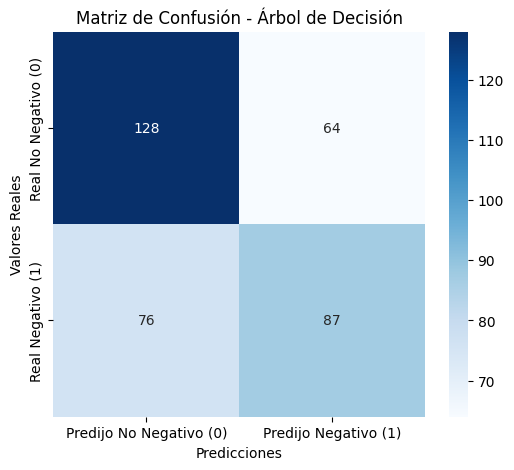


Reporte de Clasificación:
              precision    recall  f1-score   support

 No Negativo       0.63      0.67      0.65       192
    Negativo       0.58      0.53      0.55       163

    accuracy                           0.61       355
   macro avg       0.60      0.60      0.60       355
weighted avg       0.60      0.61      0.60       355



In [36]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Vectorizar el texto (convertir a matriz numérica)
vectorizer = CountVectorizer(min_df=5, max_df=0.9)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# Crear y entrenar el modelo de Árbol de Decisión
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train_vec, y_train)

# Realizar predicciones
y_pred = tree_model.predict(X_test_vec)

# Calcular métricas
acc = accuracy_score(y_test, y_pred)
print(f"Exactitud del modelo: {acc:.2f}")

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)

# Mostrar matriz de confusión con etiquetas personalizadas
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Predijo No Negativo (0)", "Predijo Negativo (1)"],
            yticklabels=["Real No Negativo (0)", "Real Negativo (1)"])
plt.xlabel("Predicciones")
plt.ylabel("Valores Reales")
plt.title("Matriz de Confusión - Árbol de Decisión")
plt.show()

# Reporte de clasificación
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred, target_names=["No Negativo", "Negativo"]))

MODELO DE CLASIFICACIÓN RANDOM FOREST

Exactitud (Accuracy): 0.66
Precisión: 0.66
Recall: 0.66
F1-Score: 0.66


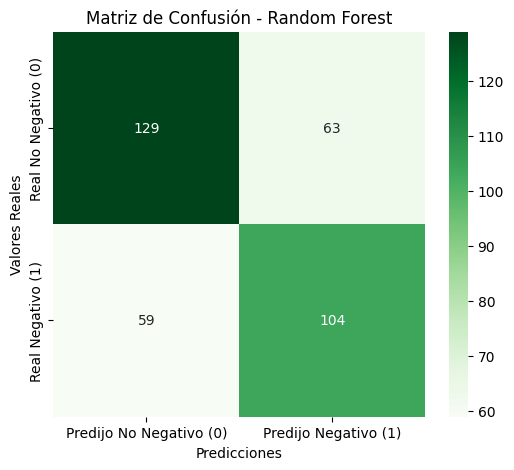


Reporte de Clasificación:
              precision    recall  f1-score   support

 No Negativo       0.69      0.67      0.68       192
    Negativo       0.62      0.64      0.63       163

    accuracy                           0.66       355
   macro avg       0.65      0.65      0.65       355
weighted avg       0.66      0.66      0.66       355



In [38]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Vectorizar los textos (usa el mismo vectorizador que antes o uno nuevo)
vectorizer = CountVectorizer(min_df=5, max_df=0.9)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# Crear y entrenar el modelo Random Forest
model_B = RandomForestClassifier(n_estimators=200, random_state=42)
model_B.fit(X_train_vec, y_train)

# Predicciones
y_pred_B = model_B.predict(X_test_vec)

# Métricas de desempeño
acc_B = accuracy_score(y_test, y_pred_B)
prec_B = precision_score(y_test, y_pred_B, average='weighted')
rec_B = recall_score(y_test, y_pred_B, average='weighted')
f1_B = f1_score(y_test, y_pred_B, average='weighted')

print(f"Exactitud (Accuracy): {acc_B:.2f}")
print(f"Precisión: {prec_B:.2f}")
print(f"Recall: {rec_B:.2f}")
print(f"F1-Score: {f1_B:.2f}")

# Matriz de confusión
cm_B = confusion_matrix(y_test, y_pred_B)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_B, annot=True, fmt='d', cmap='Greens',
            xticklabels=["Predijo No Negativo (0)", "Predijo Negativo (1)"],
            yticklabels=["Real No Negativo (0)", "Real Negativo (1)"])
plt.xlabel("Predicciones")
plt.ylabel("Valores Reales")
plt.title("Matriz de Confusión - Random Forest")
plt.show()

# Reporte detallado
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred_B, target_names=["No Negativo", "Negativo"]))


MODELO DE CLASIFICACIÓN ARBOL DE DESICIÓN